# Explainable Credit Risk Assessment

## 1. Load the Data
- We will bring in the loan applicant data.
- This data has details like income, age, and loan amount.
- It also tells us who repaid and who defaulted.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

# Two harmless library messages, hidden so the outputs stay readable:
# - scikit-learn 1.6.1 passes an old option ("iprint") to SciPy's optimizer, which newer SciPy
#   simply ignores. Set as an environment variable so the parallel worker processes see it too.
# - tqdm (used by SHAP) can't draw notebook progress bars without ipywidgets.
os.environ["PYTHONWARNINGS"] = "ignore:Unknown solver options:Warning"
warnings.filterwarnings("ignore", message="Unknown solver options")
warnings.filterwarnings("ignore", message="IProgress not found")

In [2]:
df = pd.read_csv('credit_risk_dataset.csv')
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## 2. Exploratory Data Analysis (EDA)
- Here we simply look at the data before touching it.
- We want to understand it first, then work on it.

### Basic info about the data
- Check how many rows and columns we have.
- Check the data type of each column.

In [3]:
print(df.shape)
df.info()

(32581, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


### Missing values
- Find out which columns have empty or missing values.
- This tells us where we may need to fix things later.

In [4]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

### Target balance
- Check how many people defaulted vs how many repaid.
- This tells us if our data is balanced or imbalanced.

In [5]:
df['loan_status'].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

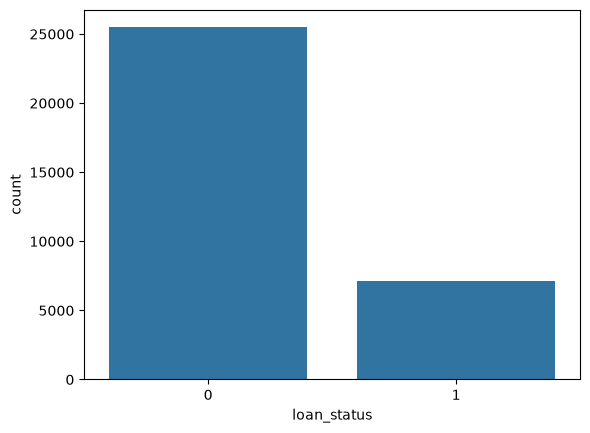

In [6]:
sns.countplot(x='loan_status', data=df)

### Outlier check
- Look for values that seem impossible, like age 144.
- These are signs of bad data entries.

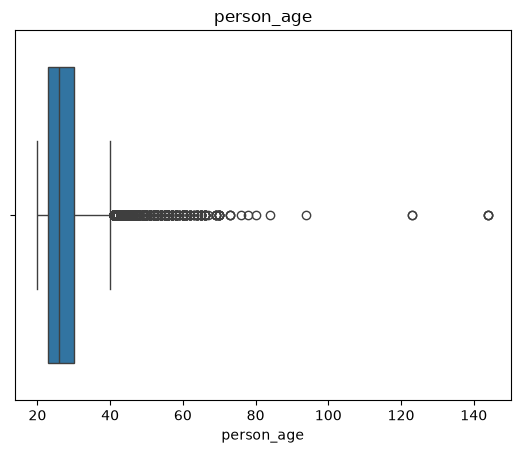

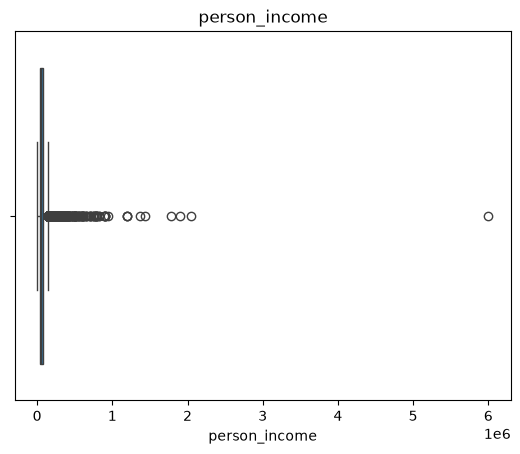

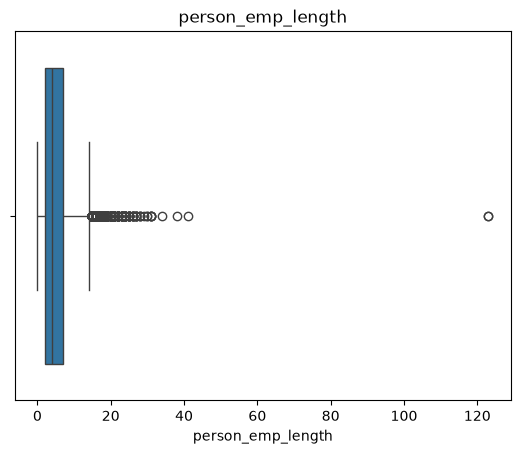

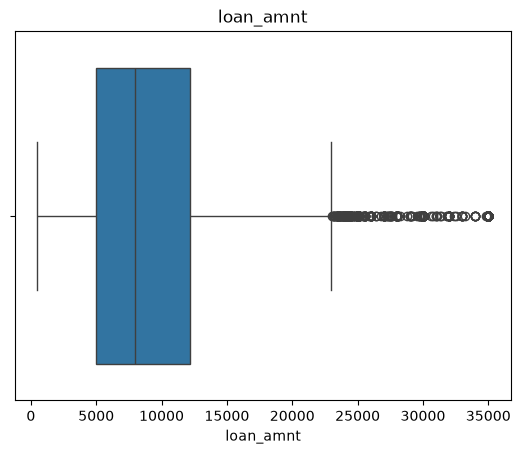

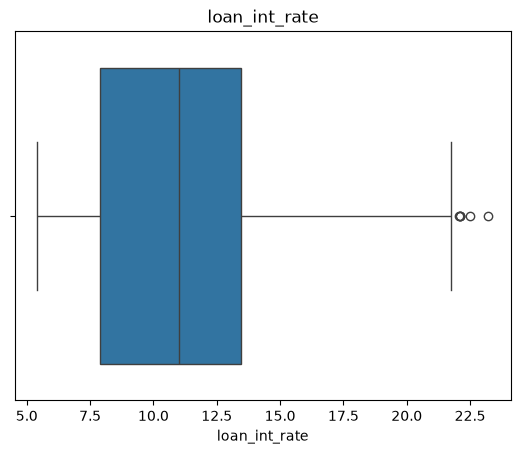

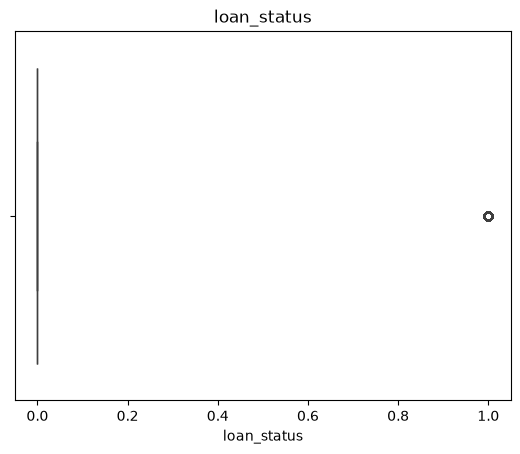

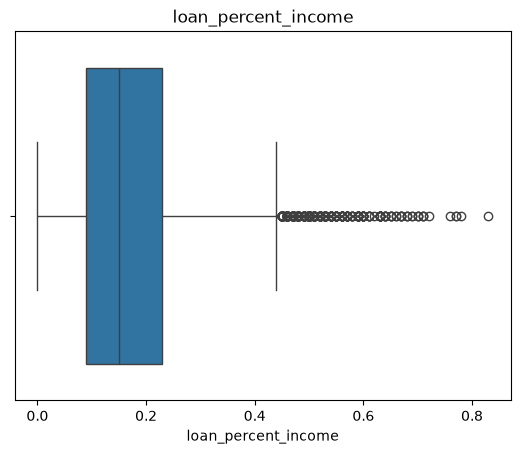

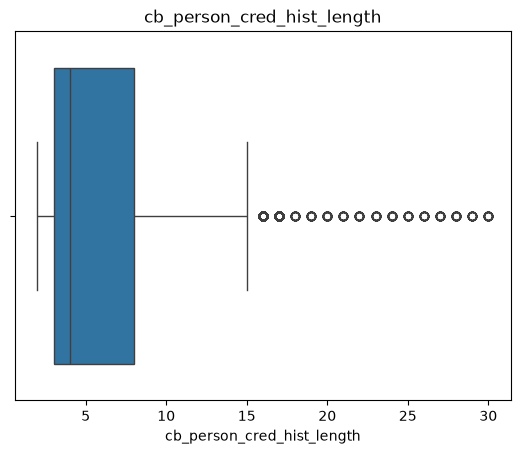

In [7]:
numerical_cols = df.select_dtypes(include=np.number).columns

for col in numerical_cols:
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

In [8]:
(df['person_age'] > 100).sum()

np.int64(5)

In [9]:
(df['person_emp_length'] > 60).sum()

np.int64(2)

In [10]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


### Correlation check
- See how strongly features are related to each other.
- This helps us spot repeated or linked information.

<Axes: >

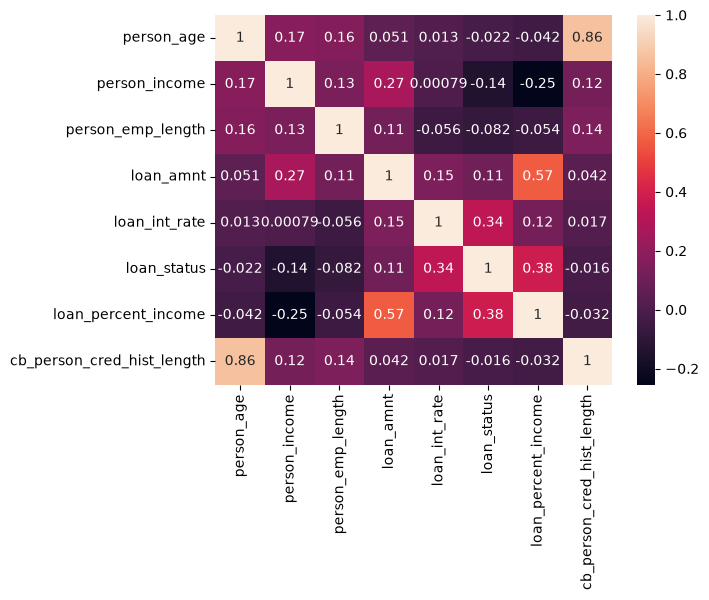

In [11]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

## 3. Data Validation & Outlier Handling
- Here we clean the data properly.
- We remove duplicate rows.
- We remove rows with an impossible age or work experience.
- We remove rows with zero or negative income and loan amount.
- We check if the interest rate looks realistic.
- We also flag rows where numbers don't add up correctly.

In [12]:
df_copy = df.copy()
print(f"Original rows : {df_copy.shape[0]}")

# Remove duplicate rows
df_copy.drop_duplicates(inplace=True)
print(f"Rows after removing duplicates : {df_copy.shape[0]}")

# Keep ages between 18 and 100
df_copy = df_copy[df_copy['person_age'].between(18, 100)]

# Employment length can't be more than age, and more than 60 years is an outlier.
# Rows with MISSING employment length are kept (the imputer fills them later).
# A plain `<=` filter would silently drop every NaN row, because NaN <= x is False.
emp = df_copy['person_emp_length']
df_copy = df_copy[emp.isna() | ((emp <= df_copy['person_age']) & (emp <= 60))]

# Remove rows with zero or negative income and loan amount
df_copy = df_copy[(df_copy['person_income'] > 0) & (df_copy['loan_amnt'] > 0)]

# Interest rate sanity check
print(f"Interest rate range : {df_copy['loan_int_rate'].min()} - {df_copy['loan_int_rate'].max()}")
print(f"Rows after cleaning : {df_copy.shape[0]}")

Original rows : 32581
Rows after removing duplicates : 32416
Interest rate range : 5.42 - 23.22
Rows after cleaning : 32409


## 4. Features, Target & Train-Test Split
- We separate the data into input features and the target.
- The target is whether the applicant defaulted or not.
- We split the data into a training part and a testing part.
- The model learns from the training part only.

In [13]:
X = df_copy.drop('loan_status', axis=1)
y = df_copy['loan_status'] #1, 0

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [15]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                     'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

## 5. Handle Class Imbalance
- Very few people actually default in this data.
- If we ignore this, the model may just favor the majority class.
- We give more importance to the minority class during training.
- This helps the model actually learn to spot defaulters.

In [16]:
# 0 -> repaid (majority), 1 -> defaulted (minority)
neg, pos = np.bincount(y_train)
scale_weights = neg / pos

In [17]:
scale_weights

np.float64(3.572663139329806)

## 6. Data Preprocessing — Pipelines & Column Transformer
- Raw data is not ready for a model directly.
- We need to prepare numeric and text columns differently.
- We will build a Pipeline for each model.
- We will use ColumnTransformer to apply different steps to different columns.

### Preprocessing for Logistic Regression
- Fill missing numeric values.
- Scale numeric values, since this model is sensitive to scale.
- Convert category columns into numbers using one-hot encoding.

In [18]:
#Logistic Regression : impute + SCALE Numeric, impute + One-Hot-Encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_lr = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_cols),

        #Pipeline - for Categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])


### Preprocessing for XGBoost
- Fill missing numeric values.
- No scaling needed here, since tree models don't need it.
- Convert category columns into numbers using one-hot encoding.

In [19]:
#XGBoost: Impute numeric only (No Scaling), impute + One - Hot Encoding

preprocessor_xg = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numeric_cols),

        #Pipeline - for Categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])


## 7. Evaluation Helper Function
- We build one common function to check any model's performance.
- It will show accuracy, precision, recall, F1 score, and more.
- It will also show a confusion matrix and a precision-recall curve.

In [20]:
# One helper to evaluate any model on the test set

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             precision_recall_curve)

def evaluate_model(model_name, model, X_test, y_test, threshold=None):
    y_pred_prob = model.predict_proba(X_test)[:, 1]

    if threshold is not None:
        # same rule as the API: probability >= threshold -> high risk
        y_pred = (y_pred_prob >= threshold).astype(int)
    else:
        y_pred = model.predict(X_test)

    # Metrics
    accuracy  = accuracy_score(y_test, y_pred)    # overall correctness
    precision = precision_score(y_test, y_pred)   # when the model says 1, how often it is really 1
    recall    = recall_score(y_test, y_pred)      # of the real 1s, how many the model catches
    f1        = f1_score(y_test, y_pred)          # harmonic mean of precision and recall
    roc_auc   = roc_auc_score(y_test, y_pred_prob)

    print(f"{model_name} Metrics:")
    if threshold is not None:
        print(f"Used Threshold : {threshold:.3f}")
    print(f"Accuracy  : {accuracy:.3f}")
    print(f"Precision : {precision:.3f}")
    print(f"Recall    : {recall:.3f}")
    print(f"F1        : {f1:.3f}")
    print(f"ROC-AUC   : {roc_auc:.3f}")
    print()
    print(f"{model_name} Classification Report:")
    print(classification_report(y_test, y_pred))

    # Confusion matrix
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d")
    plt.title(f"{model_name} Confusion Matrix")
    plt.ylabel("Actual Values")
    plt.xlabel("Predicted Values")
    plt.show()

    # Precision-Recall curve
    pr_precisions, pr_recalls, _ = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(pr_recalls, pr_precisions)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.show()

    # Returned so the numbers can be logged to MLflow (section 18)
    return {"accuracy": accuracy, "precision": precision, "recall": recall,
            "f1": f1, "roc_auc": roc_auc}

## 8. Stratified Cross-Validation
- One single train-test split may not be reliable.
- We split the training data into five folds instead.
- Each fold keeps the same default vs repaid ratio.
- We check the model's score across all folds.

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'roc_auc':'roc_auc', 'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1'}

In [22]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

In [23]:
# !pip install xgboost   # only needed if xgboost is not installed
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1,
        scale_pos_weight=scale_weights, random_state=42,
        n_jobs=1   # single thread: same model on any number of CPU cores
    ))
])

In [24]:
cv_scores = {}   # kept for MLflow (section 18)
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xgb_cv_pipeline)]:
    cv_results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_scores[cv_name] = {m: cv_results[f'test_{m}'].mean() for m in scoring}

    print(cv_name)
    print(f"ROC-AUC   : {cv_results['test_roc_auc'].mean():.3f}")
    print(f"Accuracy  : {cv_results['test_accuracy'].mean():.3f}")
    print(f"Precision : {cv_results['test_precision'].mean():.3f}")
    print(f"Recall    : {cv_results['test_recall'].mean():.3f}")
    print(f"F1        : {cv_results['test_f1'].mean():.3f}")
    print()

Logistic Regression
ROC-AUC   : 0.870
Accuracy  : 0.812
Precision : 0.550
Recall    : 0.775
F1        : 0.644



XGBoost
ROC-AUC   : 0.947
Accuracy  : 0.915
Precision : 0.812
Recall    : 0.794
F1        : 0.803



## 9. Baseline Model — Logistic Regression
- We start with a simple model first.
- This becomes our benchmark to beat.
- We train it and check its score on the test data.

In [25]:
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [26]:
# Evaluate the Logistic model on the test set

Baseline Logistic Model Metrics:
Accuracy  : 0.806
Precision : 0.539
Recall    : 0.782
F1        : 0.638
ROC-AUC   : 0.872

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.81      0.87      5064
           1       0.54      0.78      0.64      1418

    accuracy                           0.81      6482
   macro avg       0.73      0.80      0.75      6482
weighted avg       0.84      0.81      0.82      6482



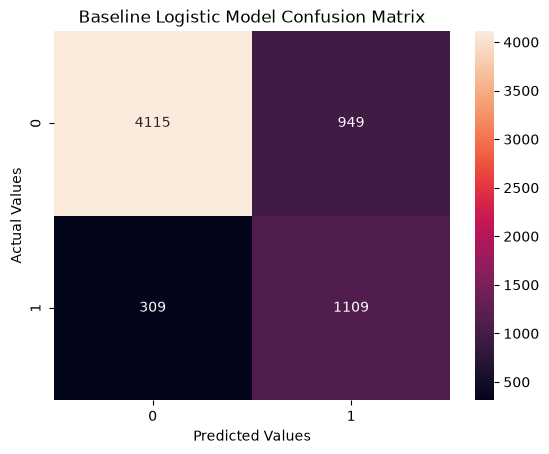

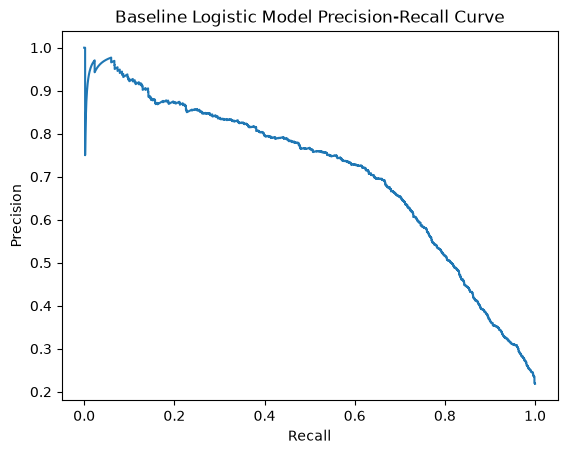

In [27]:
lr_test_metrics = evaluate_model("Baseline Logistic Model", baseline_model ,X_test, y_test)

## 10. XGBoost Hyperparameter Tuning
- Now we move to a stronger model, XGBoost.
- A model has many settings called hyperparameters.
- We search for the best combination of these settings.
- We use cross-validation while searching, so the result is reliable.
- Each XGBoost model trains on a single thread (`n_jobs=1`). With more threads, the result changes
  with the number of CPU cores, so machines with different core counts would train different models
  from the same code. The operating system also changes the result slightly, so the deployed model is
  trained in a fixed Linux Docker image (`Dockerfile.train`).

In [28]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(learning_rate=0.1,
        scale_pos_weight=scale_weights, random_state=42,
        n_jobs=1))   # single thread: same model on any number of CPU cores
# RandomizedSearchCV below still trains many candidates in parallel (n_jobs=-1).
])

In [29]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6,0.4), #Rows sampling
    "classifier__colsample_bytree" :uniform(0.6,0.4), #column sampling
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0 , 5)
}
# lower gamma -> more splits -> complex tree -> higher overfitting risk
# higher gamma -> less splits ->  simpler tree -> low overfitting

In [30]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1,
    random_state=42   # same search every run, so results are reproducible
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x72ad33278a50>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x72ad35c3b620>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x72ad33278690>},
                   random_state=42, scoring='average_precision', verbose=1)

In [31]:
print(f"Best CV average precision after tuning : {random_search.best_score_:.3f}")

Best CV average precision after tuning : 0.904


In [32]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.8493192507310232),
 'classifier__gamma': np.float64(1.654490124263246),
 'classifier__learning_rate': np.float64(0.04177917514301182),
 'classifier__max_depth': 8,
 'classifier__min_child_weight': 8,
 'classifier__n_estimators': 442,
 'classifier__subsample': np.float64(0.8918424713352255)}

## 11. Compare Both Models Side by Side
- We now compare Logistic Regression and tuned XGBoost on the same test set.
- Both use the default 0.5 cut-off here.
- This helps us pick the better performing model.

Logistic Regression Metrics:
Accuracy  : 0.806
Precision : 0.539
Recall    : 0.782
F1        : 0.638
ROC-AUC   : 0.872

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.81      0.87      5064
           1       0.54      0.78      0.64      1418

    accuracy                           0.81      6482
   macro avg       0.73      0.80      0.75      6482
weighted avg       0.84      0.81      0.82      6482



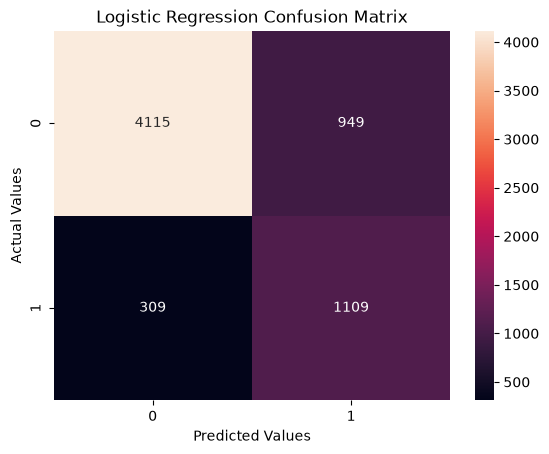

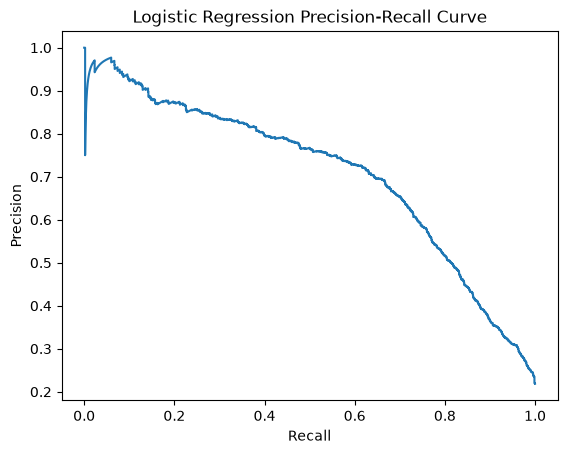

In [33]:
_ = evaluate_model("Logistic Regression", baseline_model, X_test, y_test)

XGBoost (tuned) Metrics:
Accuracy  : 0.924
Precision : 0.840
Recall    : 0.807
F1        : 0.823
ROC-AUC   : 0.954

XGBoost (tuned) Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      5064
           1       0.84      0.81      0.82      1418

    accuracy                           0.92      6482
   macro avg       0.89      0.88      0.89      6482
weighted avg       0.92      0.92      0.92      6482



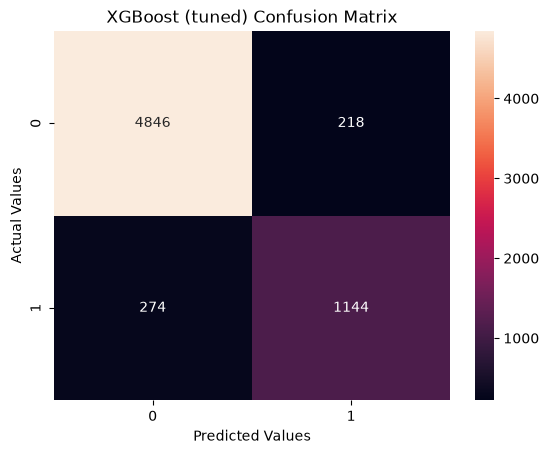

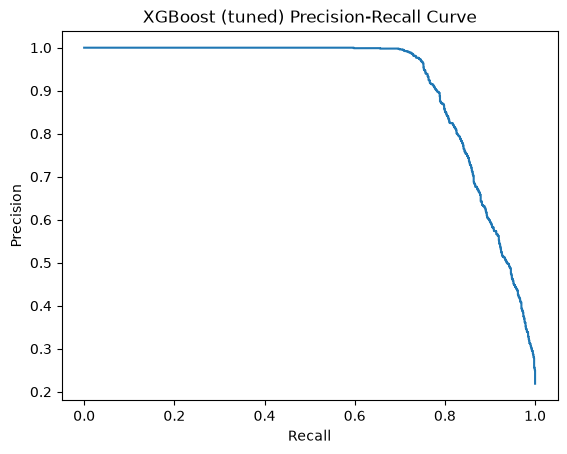

In [34]:
# Tuned XGBoost (best model from the random search)
xgb_tuned_test_metrics = evaluate_model("XGBoost (tuned)", random_search.best_estimator_, X_test, y_test)

## 12. Probability Calibration
- Sometimes a model's probability doesn't mean what it says.
- For example, 30% risk should truly mean a 30% chance.
- We check this with a calibration plot.
- We fix it if the probabilities are off.

Ways to fix a poorly calibrated model:
1. **Platt scaling / sigmoid** - adjusts the probabilities with a sigmoid curve.
2. **Isotonic regression** - learns a flexible, non-linear mapping from old to better probabilities.
3. **Temperature scaling** - softens or sharpens the confidence of neural-network predictions with one temperature value.

Here we use sigmoid (Platt) scaling.

In [35]:
# 1. Calibrate the tuned XGBoost model
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train, y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.04177917514301182),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=8,
                                                                max_leaves=None,
                                                                min_child_weight=8,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=442,
                                                                n_jobs=1,
                                                                num_parallel_tree=None, ...))]))

In [36]:
# 2. Get probabilities (same tuned model, before vs after calibration)
uncalibrated = best_model.predict_proba(X_test)[:, 1]
calibrated = calibrated_model.predict_proba(X_test)[:, 1]

In [37]:
#3. create calibration curves
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)

In [38]:
actual_cal, predicted_cal  = calibration_curve(y_test, calibrated, n_bins=10)

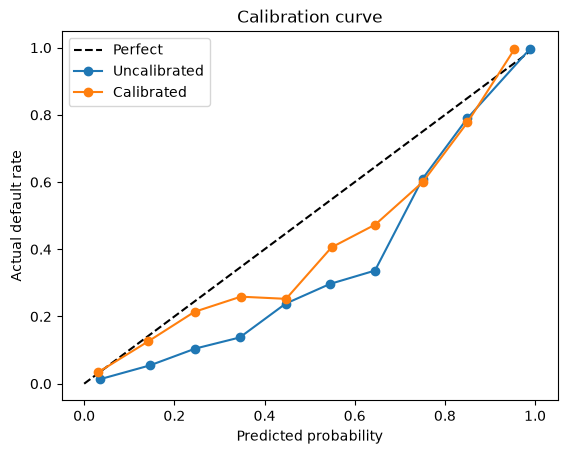

Brier score uncalibrated : 0.0608
Brier score calibrated   : 0.0511


In [39]:
# 4. Plot
plt.plot([0, 1], [0, 1], 'k--', label="Perfect")
plt.plot(predicted_uncal, actual_uncal, "o-", label="Uncalibrated")
plt.plot(predicted_cal, actual_cal, "o-", label="Calibrated")
plt.xlabel("Predicted probability")
plt.ylabel("Actual default rate")
plt.title("Calibration curve")
plt.legend()
plt.show()

# Brier score: lower is better
from sklearn.metrics import brier_score_loss
print(f"Brier score uncalibrated : {brier_score_loss(y_test, uncalibrated):.4f}")
print(f"Brier score calibrated   : {brier_score_loss(y_test, calibrated):.4f}")

## 13. Optimizing the Classification Threshold
- The model gives a probability, not a direct yes or no.
- We decide a cut-off point to turn it into a decision.
- The cut-off is picked on out-of-fold predictions from the TRAINING data only,
  so the test set stays unseen and the test scores stay honest.
- It is picked on the calibrated model, because that is the model we save and serve.
- First we find the cut-off with the best F1 score. F1 treats both kinds of mistakes as equally bad.
- Then we pick the cut-off that makes the lender the most money, because the two mistakes
  cost very different amounts (13b). That one is deployed.

Best-F1 threshold (from training OOF) : 0.604
Calibrated XGBoost (best-F1 cut-off) Metrics:
Used Threshold : 0.604
Accuracy  : 0.940
Precision : 0.957
Recall    : 0.758
F1        : 0.846
ROC-AUC   : 0.953

Calibrated XGBoost (best-F1 cut-off) Classification Report:


              precision    recall  f1-score   support

           0       0.94      0.99      0.96      5064
           1       0.96      0.76      0.85      1418

    accuracy                           0.94      6482
   macro avg       0.95      0.87      0.90      6482
weighted avg       0.94      0.94      0.94      6482



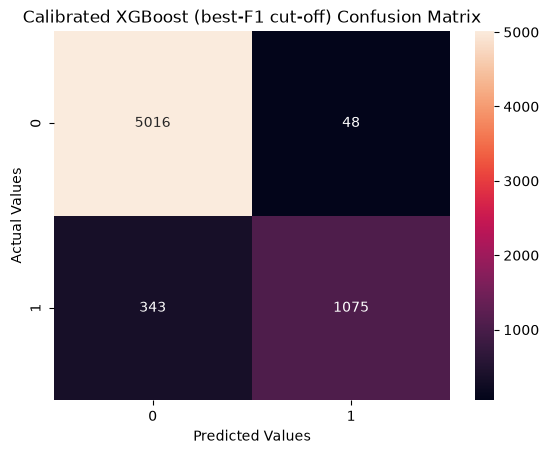

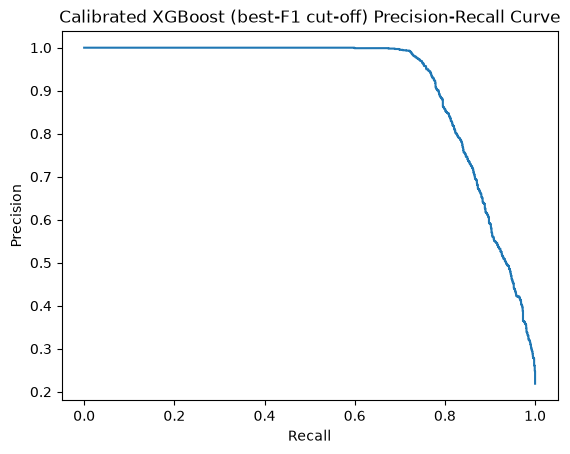

In [40]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

# 1. Out-of-fold probabilities on the training data (each row is predicted by a model that never saw it)
oof_prob = cross_val_predict(clone(calibrated_model), X_train, y_train,
                             cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

# 2. Precision and recall for every possible threshold
precisions, recalls, thresholds = precision_recall_curve(y_train, oof_prob)

# 3. F1 score for each threshold
f1 = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

# 4. Threshold with the highest F1 (the last precision/recall point has no threshold)
best = np.argmax(f1[:-1])
f1_threshold = float(thresholds[best])
print(f"Best-F1 threshold (from training OOF) : {f1_threshold:.3f}")

# 5. How the best-F1 cut-off does on the untouched test set
f1_test_metrics = evaluate_model("Calibrated XGBoost (best-F1 cut-off)", calibrated_model, X_test, y_test, f1_threshold)

### 13b. Cost-Based Threshold
The two mistakes don't cost the same:

| Mistake | What happens | Cost to the lender |
|---|---|---|
| Approve someone who defaults | Part of the loan is lost | **LGD x loan amount** |
| Reject someone who would repay | The interest is never earned | **interest rate x loan amount x term** |

Example: a 10,000 loan at 11%. A default loses about 6,000, while a wrongly rejected good customer costs about 1,100
in lost interest. So missing a defaulter is about 5 times worse.

**Assumptions** (not in the data, so they are set here and can be changed):
- **LGD (loss given default) = 60%**: when a borrower defaults, the lender loses 60% of the loan and recovers 40%.
- **Loan term = 1 year**: a good loan earns one year of interest.
- A missing interest rate is filled with the median rate of the applicant's loan grade (from the training data).

We pick the cut-off that gives the **highest total net profit** on the training out-of-fold predictions:
interest earned on approved good loans minus money lost on approved defaulters.

Best-F1 cut-off      : 0.604
Max-profit cut-off   : 0.170   (LGD 60%, 1-year term)


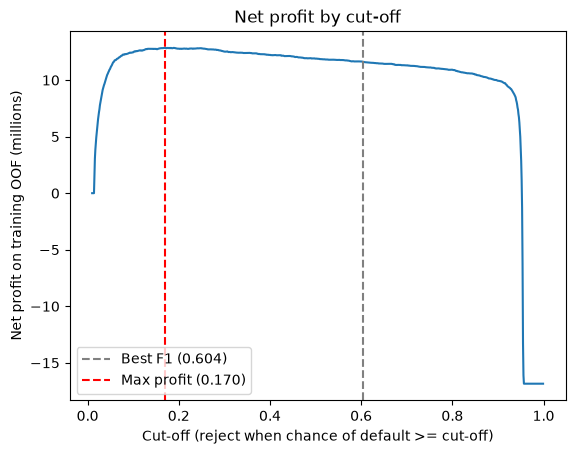

In [41]:
# Business assumptions - change them here to see how the cut-off moves
LGD = 0.60              # share of the loan lost when a borrower defaults
LOAN_TERM_YEARS = 1     # years of interest earned on a good loan

# Median interest rate per loan grade, from the TRAINING data, for applicants with no rate
grade_rate = X_train.groupby("loan_grade")["loan_int_rate"].median()

def money(X, lgd=LGD):
    """Per applicant: money lost if we approve a defaulter, money earned if we approve a good payer."""
    rate = X["loan_int_rate"].fillna(X["loan_grade"].map(grade_rate)) / 100
    loss_if_default = (lgd * X["loan_amnt"]).to_numpy()
    profit_if_repaid = (rate * LOAN_TERM_YEARS * X["loan_amnt"]).to_numpy()
    return loss_if_default, profit_if_repaid

def net_profit(y, prob, threshold, loss, profit):
    """Approve when the chance of default is below the cut-off (same rule as the API)."""
    approved = prob < threshold
    return profit[approved & (y == 0)].sum() - loss[approved & (y == 1)].sum()

def best_profit_threshold(y, prob, loss, profit):
    grid = np.round(np.arange(0.01, 1.0, 0.001), 3)
    profits = np.array([net_profit(y, prob, t, loss, profit) for t in grid])
    return float(grid[np.argmax(profits)]), grid, profits

y_tr = y_train.to_numpy()
train_loss, train_profit = money(X_train)
cost_threshold, grid, oof_profits = best_profit_threshold(y_tr, oof_prob, train_loss, train_profit)

print(f"Best-F1 cut-off      : {f1_threshold:.3f}")
print(f"Max-profit cut-off   : {cost_threshold:.3f}   (LGD {LGD:.0%}, {LOAN_TERM_YEARS}-year term)")

plt.plot(grid, oof_profits / 1e6)
plt.axvline(f1_threshold, color="grey", linestyle="--", label=f"Best F1 ({f1_threshold:.3f})")
plt.axvline(cost_threshold, color="red", linestyle="--", label=f"Max profit ({cost_threshold:.3f})")
plt.xlabel("Cut-off (reject when chance of default >= cut-off)")
plt.ylabel("Net profit on training OOF (millions)")
plt.title("Net profit by cut-off")
plt.legend()
plt.show()

In [42]:
# Compare decision rules on the untouched TEST set
test_loss, test_profit = money(X_test)
y_te = y_test.to_numpy()
test_prob = calibrated_model.predict_proba(X_test)[:, 1]

def policy_row(name, approved):
    return {
        "rule": name,
        "approved": int(approved.sum()),
        "rejected": int((~approved).sum()),
        "defaulters_approved": int((approved & (y_te == 1)).sum()),
        "good_rejected": int((~approved & (y_te == 0)).sum()),
        "net_profit": round(float(test_profit[approved & (y_te == 0)].sum()
                                  - test_loss[approved & (y_te == 1)].sum())),
    }

policy_table = pd.DataFrame([
    policy_row("Approve everyone", np.ones(len(y_te), dtype=bool)),
    policy_row(f"Best-F1 cut-off ({f1_threshold:.3f})", test_prob < f1_threshold),
    policy_row(f"Max-profit cut-off ({cost_threshold:.3f})", test_prob < cost_threshold),
    policy_row("Perfect model (knows the future)", y_te == 0),
])
policy_table

,rule,approved,rejected,defaulters_approved,good_rejected,net_profit
0,Approve everyone,6482,0,1418,0,-4318340
1,Best-F1 cut-off (0.604),5359,1123,343,48,3071871
2,Max-profit cut-off (0.170),4718,1764,189,535,3330865
3,Perfect model (knows the future),5064,1418,0,0,5001385


In [43]:
# How much does the cut-off depend on the LGD assumption? (each one picked on training OOF)
sensitivity = []
for lgd in [0.4, 0.6, 0.8, 1.0]:
    l_tr, p_tr = money(X_train, lgd)
    t, _, _ = best_profit_threshold(y_tr, oof_prob, l_tr, p_tr)
    l_te, p_te = money(X_test, lgd)
    sensitivity.append({
        "LGD": f"{lgd:.0%}",
        "max_profit_cutoff": t,
        "test_rejected_share": round(float((test_prob >= t).mean()), 3),
        "test_net_profit": round(float(net_profit(y_te, test_prob, t, l_te, p_te))),
        "test_net_profit_with_f1_cutoff": round(float(net_profit(y_te, test_prob, f1_threshold, l_te, p_te))),
    })
pd.DataFrame(sensitivity)

,LGD,max_profit_cutoff,test_rejected_share,test_net_profit,test_net_profit_with_f1_cutoff
0,40%,0.248,0.237,3745415,3690711
1,60%,0.170,0.272,3330865,3071871
2,80%,0.132,0.298,2986493,2453031
3,100%,0.077,0.364,2619090,1834191


Calibrated XGBoost (max-profit cut-off) Metrics:
Used Threshold : 0.170
Accuracy  : 0.888
Precision : 0.697
Recall    : 0.867
F1        : 0.772
ROC-AUC   : 0.953

Calibrated XGBoost (max-profit cut-off) Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.89      0.93      5064
           1       0.70      0.87      0.77      1418

    accuracy                           0.89      6482
   macro avg       0.83      0.88      0.85      6482
weighted avg       0.90      0.89      0.89      6482



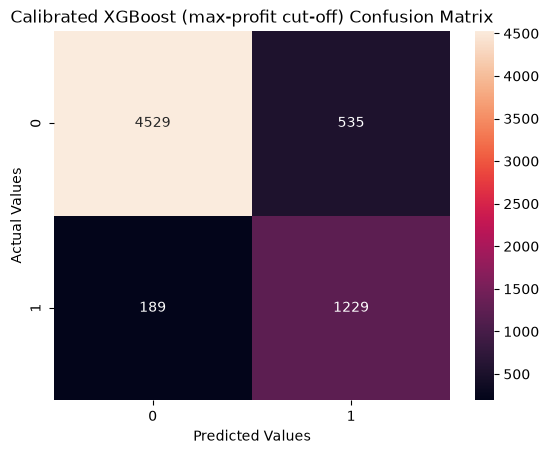

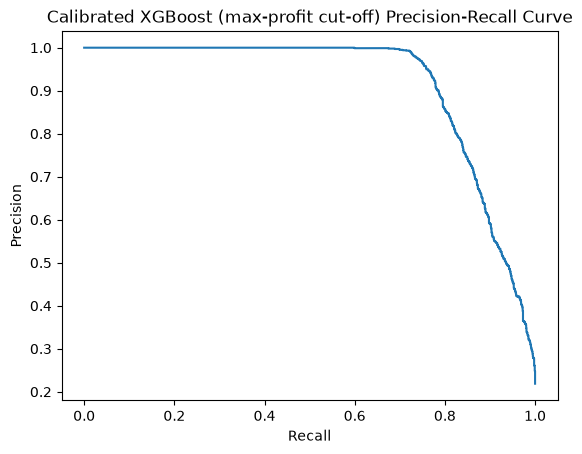

In [44]:
# The deployed cut-off: maximum profit
best_threshold = cost_threshold
final_test_metrics = evaluate_model("Calibrated XGBoost (max-profit cut-off)", calibrated_model, X_test, y_test, best_threshold)

## 14. SHAP Interpretation — Global & Local
- SHAP helps us understand why the model makes a decision.
- It is a way of explaining a "black box" model.

In [45]:
# 1. Install SHAP if not installed
# !pip install shap
import shap

In [46]:
# 2. Get the tuned XGBoost classifier out of the pipeline.
# SHAP explains the tuned model before calibration. Sigmoid calibration is a
# monotonic mapping, so feature importance and direction stay the same.
xgb_classifier = best_model.named_steps['classifier']

In [47]:
# 3. Transform X_test using the same preprocessing used for training.
X_test_transformed = best_model.named_steps['preprocessor'].transform(X_test)

In [48]:
# 4. Get feature names after one-hot encoding, so plots are readable
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()

In [49]:
#5. Convert to a dataframe for cleaner SHAP plots
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [50]:
#6. Create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)

In [51]:
# 7. Calculate SHAP values for every row in the test set
shap_values = explainer.shap_values(X_test_df)
shap_values.shape

(6482, 26)

### Global explanation
- This shows which features matter most overall.
- It also shows if a feature increases or decreases risk.

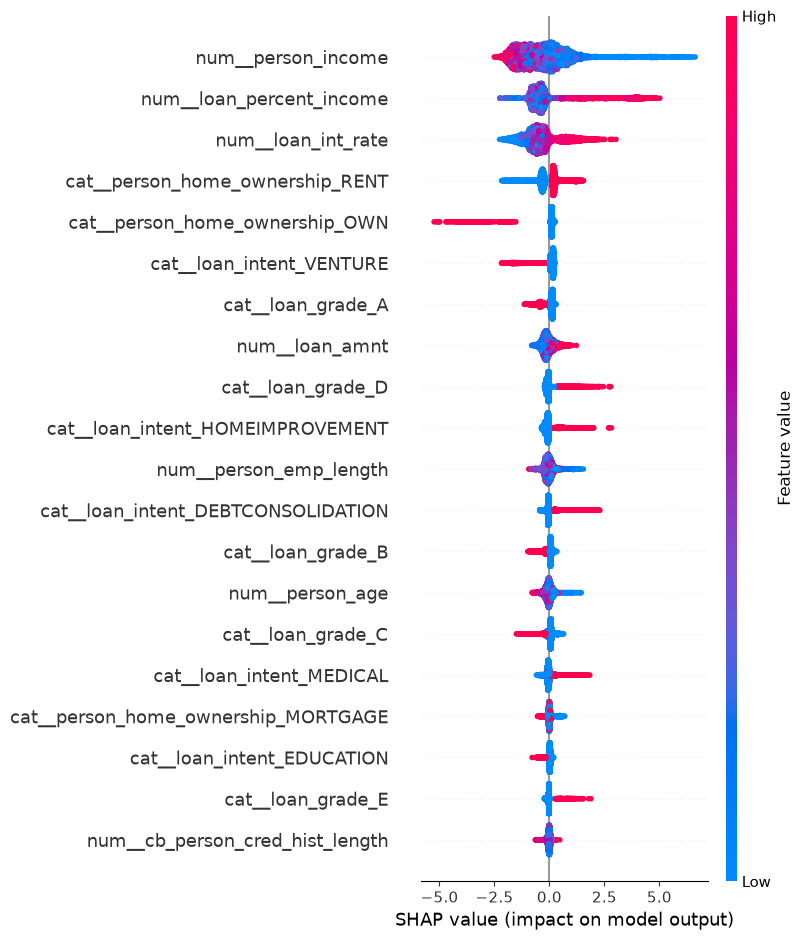

In [52]:
shap.summary_plot(shap_values, X_test_df)

### Local explanation
- This shows why one specific applicant got their score.
- It breaks the score down feature by feature.

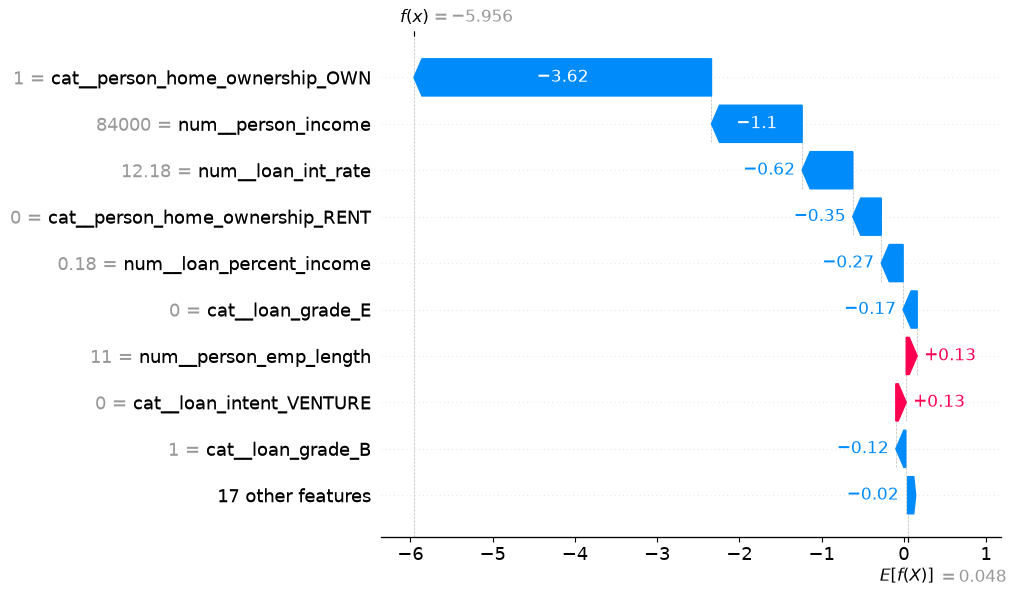

In [53]:
# 1. Pick one row to explain, e.g. the 5th applicant in the test set
row_index = 5

#2. Draw a waterfall plot showing how each feature pushed the prediction up or down.
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

## 15. Analyzing False Positives & False Negatives
- The model will not be perfect.
- False positives are safe people wrongly marked risky.
- False negatives are risky people wrongly marked safe.
- We study these cases to understand where the model struggles.

In [54]:
# Final predictions = calibrated model + chosen threshold (exactly what the API does)
y_pred = (calibrated_model.predict_proba(X_test)[:, 1] >= best_threshold).astype(int)

In [55]:
#Create a dataframe to easily compare the actual and predicted values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [56]:
#Identify False Positive : Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['actual']== 0) & (result_df['predicted']== 1)]

#Identify False Negative : Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['actual']== 1) & (result_df['predicted']== 0)]

In [57]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")

False Positive : 535
False Negative : 189


In [58]:
if len(false_negative) > len(false_positive):
    print("The model misses more defaulters (FN) than it wrongly flags safe applicants (FP).")
else:
    print("The model wrongly flags more safe applicants (FP) than it misses defaulters (FN).")

The model wrongly flags more safe applicants (FP) than it misses defaulters (FN).


## 16. Save the Final Model
- Once we are happy with the model, we save it.
- We also save the settings it needs, like the chosen threshold.
- The XGBoost part is saved in XGBoost's portable format, so the file loads on Linux, Windows and macOS.
- This saved file can now be used in a real application.

In [59]:
# Save in a portable format: a plain pickle of an XGBoost model trained on Linux
# (Colab) fails to load on Windows. model_io.py is in the project repo -
# keep it next to this notebook (in Colab, upload it first).
import joblib
from model_io import save_portable

save_portable(calibrated_model, "credit_risk_model.pkl")

Saved credit_risk_model.pkl with 6 portable XGBoost boosters


In [60]:
joblib.dump(best_threshold, "best_threshold.pkl")

['best_threshold.pkl']

## 17. How Sure Are the Test Scores? (Bootstrap Confidence Intervals)
- The test set is one sample of 6,482 applicants. A different sample would give slightly different scores.
- Bootstrap: draw 1,000 new test sets of the same size **with replacement** from the real one, and score each.
- The middle 95% of those 1,000 scores is the **95% confidence interval**.
- A narrow interval means the score is stable, not luck.
- We also compare XGBoost with Logistic Regression **on the same 1,000 resamples**. If the whole interval
  of the difference is above 0, XGBoost is really better, not just better on this one split.
- Finally, the same idea checks the money: does the max-profit cut-off really earn more than the
  best-F1 cut-off, or only on this one test set?

In [61]:
from sklearn.metrics import brier_score_loss

n_boot = 1000
rng = np.random.default_rng(42)   # fixed seed: same intervals every run

y_true = y_test.to_numpy()
xgb_prob = calibrated_model.predict_proba(X_test)[:, 1]
xgb_pred = (xgb_prob >= best_threshold).astype(int)     # deployed model + deployed cut-off
lr_prob = baseline_model.predict_proba(X_test)[:, 1]
lr_pred = (lr_prob >= 0.5).astype(int)                  # baseline at its default cut-off

def scores(y, prob, pred):
    return {
        "roc_auc":   roc_auc_score(y, prob),
        "precision": precision_score(y, pred, zero_division=0),
        "recall":    recall_score(y, pred),
        "f1":        f1_score(y, pred),
        "accuracy":  accuracy_score(y, pred),
        "brier":     brier_score_loss(y, prob),
    }

xgb_boot, lr_boot = [], []
for _ in range(n_boot):
    idx = rng.integers(0, len(y_true), len(y_true))     # one resample, used for both models
    xgb_boot.append(scores(y_true[idx], xgb_prob[idx], xgb_pred[idx]))
    lr_boot.append(scores(y_true[idx], lr_prob[idx], lr_pred[idx]))

xgb_boot, lr_boot = pd.DataFrame(xgb_boot), pd.DataFrame(lr_boot)

In [62]:
# 95% interval = 2.5th to 97.5th percentile of the 1,000 bootstrap scores
xgb_point = scores(y_true, xgb_prob, xgb_pred)
ci_table = pd.DataFrame({
    "score":    xgb_point,
    "ci_low":   xgb_boot.quantile(0.025),
    "ci_high":  xgb_boot.quantile(0.975),
}).round(3)
print("Calibrated XGBoost on the test set (cut-off %.3f), 95%% bootstrap CI:" % best_threshold)
ci_table

Calibrated XGBoost on the test set (cut-off 0.170), 95% bootstrap CI:


,score,ci_low,ci_high
roc_auc,0.953,0.946,0.960
precision,0.697,0.675,0.718
recall,0.867,0.849,0.884
f1,0.772,0.755,0.788
accuracy,0.888,0.880,0.895
brier,0.051,0.047,0.055


In [63]:
# Is XGBoost really better than Logistic Regression? Difference on the SAME resamples.
diff = xgb_boot - lr_boot
lr_point = scores(y_true, lr_prob, lr_pred)
diff_table = pd.DataFrame({
    "xgboost":        pd.Series(xgb_point),
    "logistic":       pd.Series(lr_point),
    "difference":     pd.Series(xgb_point) - pd.Series(lr_point),
    "diff_ci_low":    diff.quantile(0.025),
    "diff_ci_high":   diff.quantile(0.975),
}).round(3)
# For Brier score lower is better, so XGBoost is better when the difference is below 0.
better = np.where(diff_table.index == "brier", diff_table["diff_ci_high"] < 0, diff_table["diff_ci_low"] > 0)
diff_table["xgboost_clearly_better"] = better
diff_table

,xgboost,logistic,difference,diff_ci_low,diff_ci_high,xgboost_clearly_better
roc_auc,0.953,0.872,0.082,0.073,0.090,True
precision,0.697,0.539,0.158,0.139,0.177,True
recall,0.867,0.782,0.085,0.066,0.104,True
f1,0.772,0.638,0.134,0.119,0.151,True
accuracy,0.888,0.806,0.082,0.073,0.092,True
brier,0.051,0.139,-0.088,-0.093,-0.084,True


In [64]:
# Does the max-profit cut-off really earn more than the best-F1 cut-off? Same 1,000-resample idea.
rng_profit = np.random.default_rng(7)
gain = []
for _ in range(n_boot):
    idx = rng_profit.integers(0, len(y_true), len(y_true))
    gain.append(net_profit(y_true[idx], xgb_prob[idx], best_threshold, test_loss[idx], test_profit[idx])
                - net_profit(y_true[idx], xgb_prob[idx], f1_threshold, test_loss[idx], test_profit[idx]))
gain = np.array(gain)
profit_gain = float(net_profit(y_true, xgb_prob, best_threshold, test_loss, test_profit)
                    - net_profit(y_true, xgb_prob, f1_threshold, test_loss, test_profit))
gain_ci = (float(np.quantile(gain, 0.025)), float(np.quantile(gain, 0.975)))
print(f"Extra net profit on the test set, max-profit vs best-F1 cut-off: {profit_gain:,.0f}")
print(f"95% bootstrap CI: {gain_ci[0]:,.0f} to {gain_ci[1]:,.0f}")
print("Clearly better" if gain_ci[0] > 0 else "Not clearly better")

Extra net profit on the test set, max-profit vs best-F1 cut-off: 258,994
95% bootstrap CI: 91,238 to 431,119
Clearly better


## 18. Track the Experiment with MLflow
- Every run of this notebook is saved as one MLflow run, with a child run for each model.
- It stores the settings (params), the scores (metrics), and files like plots and the model (artifacts).
- Later you can compare runs side by side and see exactly which settings produced the saved model.
- Everything is stored locally: `mlflow.db` (runs and scores) and `mlruns/` (files). Both are git-ignored.
- To browse the runs, run `mlflow ui --backend-store-uri sqlite:///mlflow.db` and open http://127.0.0.1:5000.

In [65]:
# !pip install mlflow   # only needed if mlflow is not installed
import hashlib
import os
import platform
import subprocess
from datetime import datetime

import mlflow
import sklearn
import xgboost

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("credit-risk")

def git_commit():
    if os.environ.get("GIT_COMMIT"):   # passed in by the training container
        return os.environ["GIT_COMMIT"]
    try:
        return subprocess.run(["git", "rev-parse", "--short", "HEAD"],
                              capture_output=True, text=True, check=True).stdout.strip()
    except Exception:
        return "unknown"   # e.g. in Colab

def with_prefix(prefix, metrics):
    return {f"{prefix}_{name}": float(value) for name, value in metrics.items()}

dataset_md5 = hashlib.md5(open("credit_risk_dataset.csv", "rb").read()).hexdigest()
tuned_params = {k.replace("classifier__", ""): v for k, v in random_search.best_params_.items()}
tn, fp, fn, tp = confusion_matrix(y_test, xgb_pred).ravel()

In [66]:
with mlflow.start_run(run_name=f"training-{datetime.now():%Y-%m-%d-%H%M}") as parent_run:
    mlflow.set_tags({
        "git_commit": git_commit(),
        "dataset_md5": dataset_md5,
        "sklearn_version": sklearn.__version__,
        "xgboost_version": xgboost.__version__,
        "python_version": platform.python_version(),
        "os": platform.system(),
        # "docker" when trained with Dockerfile.train (the reproducible setup)
        "training_environment": os.environ.get("TRAINING_ENV", "local"),
    })
    mlflow.log_params({
        "rows_raw": len(df), "rows_clean": len(df_copy),
        "rows_train": len(X_train), "rows_test": len(X_test),
        "test_size": 0.2, "split_random_state": 42, "cv_folds": 5,
    })
    # The cleaned training data (MLflow stores its schema and a fingerprint, not the rows).
    # UserWarning hidden: MLflow only hints that integer columns can't hold missing values.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        mlflow.log_input(mlflow.data.from_pandas(df_copy, targets="loan_status", name="credit_risk_clean"),
                         context="training")

    # 1. Baseline
    with mlflow.start_run(run_name="logistic_regression_baseline", nested=True):
        mlflow.log_params({"model": "LogisticRegression", "class_weight": "balanced",
                           "max_iter": 1000, "threshold": 0.5})
        mlflow.log_metrics(with_prefix("cv", cv_scores["Logistic Regression"]))
        mlflow.log_metrics(with_prefix("test", lr_test_metrics))

    # 2. XGBoost with fixed settings (section 8)
    with mlflow.start_run(run_name="xgboost_untuned", nested=True):
        mlflow.log_params({"model": "XGBClassifier", "n_estimators": 300, "max_depth": 5,
                           "learning_rate": 0.1, "scale_pos_weight": float(scale_weights)})
        mlflow.log_metrics(with_prefix("cv", cv_scores["XGBoost"]))

    # 3. Hyperparameter search (section 10): best settings + every candidate as a CSV
    with mlflow.start_run(run_name="xgboost_tuned", nested=True):
        mlflow.log_params({"model": "XGBClassifier", "search": "RandomizedSearchCV",
                           "search_n_iter": 150, "search_scoring": "average_precision",
                           "search_random_state": 42, "scale_pos_weight": float(scale_weights),
                           **tuned_params})
        mlflow.log_metric("cv_average_precision", float(random_search.best_score_))
        mlflow.log_metrics(with_prefix("test", xgb_tuned_test_metrics))
        candidates = pd.DataFrame(random_search.cv_results_).sort_values("rank_test_score")
        mlflow.log_table(candidates.drop(columns="params"), artifact_file="search_candidates.json")

    # 4. Final model: calibrated XGBoost + chosen cut-off (what the API serves)
    with mlflow.start_run(run_name="calibrated_xgboost_final", nested=True):
        mlflow.log_params({"model": "CalibratedClassifierCV(XGBClassifier)",
                           "calibration_method": "sigmoid", "calibration_cv": 5,
                           "threshold": round(best_threshold, 6),
                           "threshold_rule": "max net profit on out-of-fold training predictions",
                           "f1_threshold": round(f1_threshold, 6),
                           "lgd": LGD, "loan_term_years": LOAN_TERM_YEARS,
                           "bootstrap_resamples": n_boot, **tuned_params})
        mlflow.log_metrics({
            "brier_uncalibrated": brier_score_loss(y_test, uncalibrated),
            "brier_calibrated": brier_score_loss(y_test, calibrated),
            "test_true_positives": int(tp), "test_false_positives": int(fp),
            "test_true_negatives": int(tn), "test_false_negatives": int(fn),
        })
        mlflow.log_metrics(with_prefix("test", final_test_metrics))
        mlflow.log_metrics(with_prefix("test_at_f1_threshold", f1_test_metrics))
        mlflow.log_metrics({
            "test_net_profit": float(policy_table.loc[2, "net_profit"]),
            "test_net_profit_f1_threshold": float(policy_table.loc[1, "net_profit"]),
            "test_profit_gain_vs_f1": profit_gain,
            "test_profit_gain_ci_low": gain_ci[0], "test_profit_gain_ci_high": gain_ci[1],
        })
        mlflow.log_table(policy_table, artifact_file="decision_rules_test.json")
        mlflow.log_table(pd.DataFrame(sensitivity), artifact_file="lgd_sensitivity.json")
        mlflow.log_metrics({f"test_{m}_ci_low": float(ci_table.loc[m, "ci_low"]) for m in ci_table.index})
        mlflow.log_metrics({f"test_{m}_ci_high": float(ci_table.loc[m, "ci_high"]) for m in ci_table.index})
        mlflow.log_table(diff_table.reset_index(names="metric"), artifact_file="xgboost_vs_logistic.json")

        # Plots
        fig, ax = plt.subplots()
        ax.plot([0, 1], [0, 1], "k--", label="Perfect")
        ax.plot(predicted_uncal, actual_uncal, "o-", label="Uncalibrated")
        ax.plot(predicted_cal, actual_cal, "o-", label="Calibrated")
        ax.set_xlabel("Predicted probability"); ax.set_ylabel("Actual default rate")
        ax.set_title("Calibration curve"); ax.legend()
        mlflow.log_figure(fig, "calibration_curve.png"); plt.close(fig)

        plt.close("all")   # start from an empty figure, so no earlier plot leaks in
        shap.summary_plot(shap_values, X_test_df, show=False)
        mlflow.log_figure(plt.gcf(), "shap_summary.png"); plt.close("all")

        # The exact files the API loads (portable format, see model_io.py)
        mlflow.log_artifact("credit_risk_model.pkl", artifact_path="model")
        mlflow.log_artifact("best_threshold.pkl", artifact_path="model")

print(f"Logged run {parent_run.info.run_id} to experiment 'credit-risk'")

Logged run 542a10b8a4134c40982db4247b35d45b to experiment 'credit-risk'


In [67]:
# All runs so far, newest first: a quick comparison without opening the UI
runs = mlflow.search_runs(experiment_names=["credit-risk"],
                          filter_string=f"tags.mlflow.parentRunId = '{parent_run.info.run_id}'")
cols = ["tags.mlflow.runName", "metrics.cv_roc_auc", "metrics.cv_f1", "metrics.cv_average_precision",
        "metrics.test_roc_auc", "metrics.test_precision", "metrics.test_recall", "metrics.test_f1"]
runs[[c for c in cols if c in runs.columns]].round(3)

,tags.mlflow.runName,metrics.cv_roc_auc,metrics.cv_f1,metrics.cv_average_precision,metrics.test_roc_auc,metrics.test_precision,metrics.test_recall,metrics.test_f1
0,calibrated_xgboost_final,NaN,NaN,NaN,0.953,0.697,0.867,0.772
1,xgboost_tuned,NaN,NaN,0.904,0.954,0.840,0.807,0.823
2,xgboost_untuned,0.947,0.803,NaN,NaN,NaN,NaN,NaN
3,logistic_regression_baseline,0.870,0.644,NaN,0.872,0.539,0.782,0.638
